# Flight Delay Prediction – k-NN Modelling

## 1. Introduction

The objective of this notebook is to develop a baseline
machine learning model using k-Nearest Neighbors (k-NN).

The model predicts whether a flight will be delayed by
15 minutes or more (DEP_DEL15).

The prepared dataset is divided chronologically into
training and testing data to evaluate the model on
later flights.

In [1]:
from scipy.sparse import load_npz
import numpy as np

# loading the prepared input features
X_train = load_npz("prepared_data/X_train.npz")
X_test = load_npz("prepared_data/X_test.npz")

# loading the target values
y_train = np.load("prepared_data/y_train.npy")
y_test = np.load("prepared_data/y_test.npy")

# check the dataset dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Training features: (404662, 699)
Testing features: (118773, 699)
Training labels: (404662,)
Testing labels: (118773,)


## 2. Model Training

A k-Nearest Neighbors (k-NN) classifier is used as the
baseline model for predicting flight departure delays.

For this first iteration, k=5 is selected as a simple
starting value. The model will use the five nearest
historical flights to classify a new flight.


In [2]:
from sklearn.neighbors import KNeighborsClassifier

# creating the k-NN classifier
knn = KNeighborsClassifier(n_neighbors=5)

print(knn)


KNeighborsClassifier()


In [3]:
# training k-NN using the training dataset
knn.fit(X_train, y_train)

print("Model training completed")


Model training completed


## 3. Making Predictions

The trained k-NN model is used to predict flight delays
on unseen test data.

An initial sample of 100 test flights is used to verify
that the model can generate predictions before
evaluating a larger test set.

In [4]:
# selecting the first 100 flights from the test dataset
X_test_sample = X_test[:100]
y_test_sample = y_test[:100]

# predicting whether these flights will be delayed
y_pred_sample = knn.predict(X_test_sample)

print("Predictions:", y_pred_sample[:10])
print("Actual:     ", y_test_sample[:10])


Predictions: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Actual:      [0. 1. 0. 0. 1. 0. 0. 0. 0. 0.]


In [5]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(
    y_test_sample,
    y_pred_sample
)

print(f"Accuracy: {accuracy:.2%}")


Accuracy: 81.00%


## 4. Initial Model Evaluation

A confusion matrix is used to evaluate the model's
predictions on the initial 100-flight test sample.

This helps identify whether the model can correctly
predict delayed flights, rather than only achieving
high accuracy by predicting the majority class.

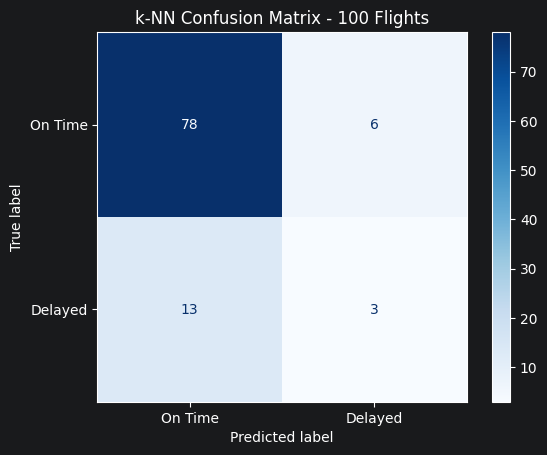

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Creating the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_sample,
    y_pred_sample,
    labels=[0, 1],
    display_labels=["On Time", "Delayed"],
    cmap="Blues"
)

plt.title("k-NN Confusion Matrix - 100 Flights")
plt.show()


## 5. Evaluation on a Larger Test Sample

The initial evaluation used 100 flights to verify that
the model could generate predictions.

A larger sample of 1,000 flights is now evaluated to
obtain a more informative estimate of the model's
performance.

Accuracy, precision, recall, F1-score and the
confusion matrix are calculated.

In [7]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# selecting 1,000 test flights
X_test_1000 = X_test[:1000]
y_test_1000 = y_test[:1000]

# making predictions
y_pred_1000 = knn.predict(X_test_1000)

# evaluating predictions
print("Accuracy:", accuracy_score(y_test_1000, y_pred_1000))

print("\nClassification Report:")
print(classification_report(
    y_test_1000,
    y_pred_1000,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_1000, y_pred_1000))


Accuracy: 0.827

Classification Report:
              precision    recall  f1-score   support

         0.0       0.87      0.95      0.90       858
         1.0       0.25      0.11      0.16       142

    accuracy                           0.83      1000
   macro avg       0.56      0.53      0.53      1000
weighted avg       0.78      0.83      0.80      1000


Confusion Matrix:
[[811  47]
 [126  16]]


## 6. Baseline Evaluation on a Random Test Sample

The initial evaluation was performed on the first
1,000 test flights.

To obtain a more representative evaluation, a random
sample of 5,000 flights is selected from the full
test dataset.

The trained k-NN model is evaluated using accuracy,
precision, recall, F1-score and a confusion matrix.

In [8]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import numpy as np

# randomly selecting 5,000 test flights
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    X_test.shape[0],
    size=5000,
    replace=False
)

# selecting the same flights and labels
X_test_5000 = X_test[sample_indices]
y_test_5000 = y_test[sample_indices]

# making predictions
y_pred_5000 = knn.predict(X_test_5000)

# evaluating the model
print("Accuracy:", accuracy_score(
    y_test_5000, y_pred_5000
))

print("\nClassification Report:")
print(classification_report(
    y_test_5000,
    y_pred_5000,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_5000,
    y_pred_5000
))


Accuracy: 0.8366

Classification Report:
              precision    recall  f1-score   support

         0.0       0.89      0.93      0.91      4432
         1.0       0.16      0.10      0.13       568

    accuracy                           0.84      5000
   macro avg       0.53      0.52      0.52      5000
weighted avg       0.81      0.84      0.82      5000


Confusion Matrix:
[[4124  308]
 [ 509   59]]


### Baseline Model Evaluation

The k-NN classifier was trained using 404,662 historical flights with 699 prepared features. The model used k=5.

The model was evaluated on a random sample of 5,000 flights from the test dataset.

The results showed an accuracy of 83.66%. However, the model performed better at identifying on-time flights than delayed flights.

For delayed flights (class 1), the model achieved a precision of 16.08%, recall of 10.39% and F1-score of 12.62%. Out of 568 actual delayed flights, only 59 were correctly identified, while 509 were incorrectly classified as on time.

The results suggest that the baseline model is biased towards predicting the majority class. Possible contributing factors include class imbalance, the high number of features and the absence of additional information such as weather conditions and so on.

This baseline provides a starting point for future iterations, where improvements to the features, class imbalance handling and alternative algorithms can be investigated.

## 7. Saving the Baseline Model

The trained k-NN model is saved so it can be reused
without repeating the training process.

This model serves as the baseline for comparison
with future machine learning models.

In [9]:
import joblib
from pathlib import Path

# Creating a folder to store models
model_folder = Path("models")
model_folder.mkdir(exist_ok=True)

# saving the trained k-NN model
joblib.dump(knn, model_folder / "knn_baseline.joblib")

print("Model saved successfully")


Model saved successfully


In [10]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# creating a table containing evaluation metrics
results = pd.DataFrame({
    "Model": ["k-NN (k=5)"],
    "Test flights": [len(y_test_5000)],
    "Accuracy": [accuracy_score(y_test_5000, y_pred_5000)],
    "Precision_Delayed": [precision_score(y_test_5000, y_pred_5000)],
    "Recall_Delayed": [recall_score(y_test_5000, y_pred_5000)],
    "F1_Delayed": [f1_score(y_test_5000, y_pred_5000)]
})

# saving the results
results.to_csv("models/knn_baseline_results.csv", index=False)

print(results.round(3))


        Model  Test flights  Accuracy  Precision_Delayed  Recall_Delayed  \
0  k-NN (k=5)          5000     0.837              0.161           0.104   

   F1_Delayed  
0       0.126  


## 8. Conclusion

In this iteration, I developed my first machine learning model using k-Nearest Neighbors (k-NN) to predict whether a flight would be delayed by 15 minutes or more.

I trained the model using 404,662 flights with 699 features and used k=5 as a baseline without hyperparameter tuning or feature selection. I evaluated the model on different test samples, with the largest containing 5,000 randomly selected flights.

The model achieved an accuracy of 83.66%. However, the confusion matrix showed that it performed much better at predicting on-time flights than delayed flights. Out of 568 delayed flights, only 59 were correctly identified, resulting in a recall of 10.39% and an F1-score of 12.62% for delayed flights.

These results show that accuracy alone is not enough to evaluate the model, especially because the dataset contains significantly more on-time flights than delayed flights. The model's performance may be affected by class imbalance, the large number of features and missing information such as weather conditions.

Through this iteration, I learned how to train a classification model, make predictions and evaluate its performance using accuracy, precision, recall, F1-score and a confusion matrix.

**For the next iteration**, I want to investigate how to improve the model's ability to identify delayed flights. I plan to explore feature selection, class imbalance handling and potentially other machine learning algorithms to compare their performance against this baseline.